## Lasso, Ridge, And Elastic Net

### 1. Dependencies

In [3]:
from prep import *
from sklearn.linear_model import Ridge, Lasso, ElasticNet

X_train, X_test, y_train, y_test, meta = load_model_data()
print(f"{X_train.shape[1]} lagged features, {len(X_train)} training quarters")

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)
27 lagged features, 92 training quarters


### 2. Ridge

In [4]:
ridge_pipe = make_pipeline(*preprocess(scale=True), Ridge())
ridge_search = tune(ridge_pipe, {"ridge__alpha": np.logspace(-3, 5, 40)}, X_train, y_train)
ridge_best = ridge_search.best_estimator_
ridge_alpha = ridge_search.best_params_["ridge__alpha"]

best params: {'ridge__alpha': np.float64(32.57020655659783)}
best CV root_mean_squared_error: 0.3841


<Axes: title={'center': 'Tuning: alpha'}, xlabel='alpha', ylabel='root mean squared error'>

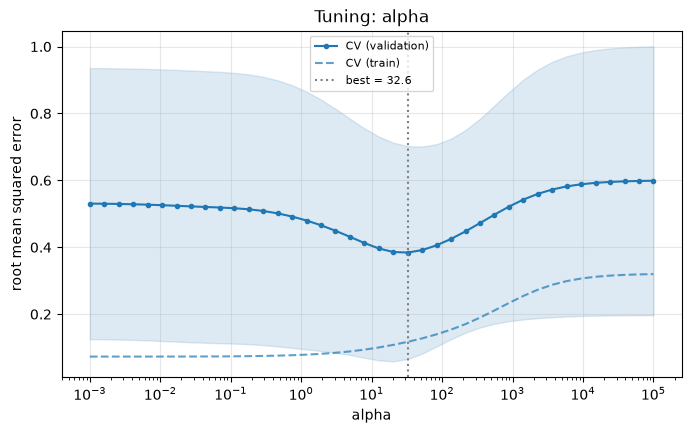

In [5]:
plot_tuning(ridge_search, "ridge__alpha")

<Axes: title={'center': "How each feature's weight changes with the hyperparameter"}, xlabel='ridge__alpha', ylabel='weight (per 1 sd of feature)'>

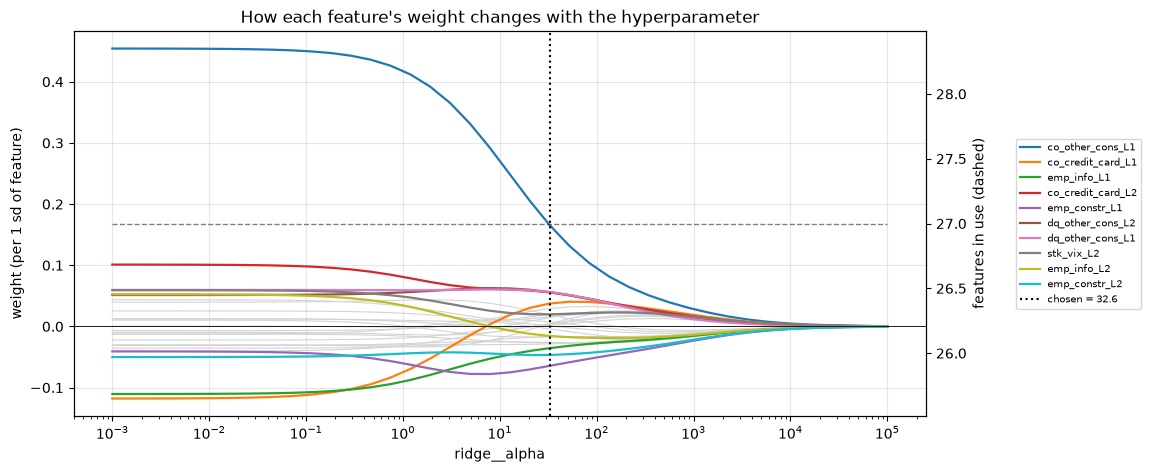

In [6]:
ridge_path = weight_path(ridge_pipe, "ridge__alpha", np.logspace(-3, 5, 40), X_train, y_train)
plot_weight_path(ridge_path, best=ridge_alpha)

> **Note:** Ridge hyperparameter approaches 0 but never reaches it. Every feature stays with some small weights.

In [7]:
score(ridge_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.202,0.142,0.884,0.609,92.0
model - test,0.372,0.169,-1.138,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.127,0.108,0.636,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


<Axes: title={'center': 'Ridge: weights at chosen alpha'}>

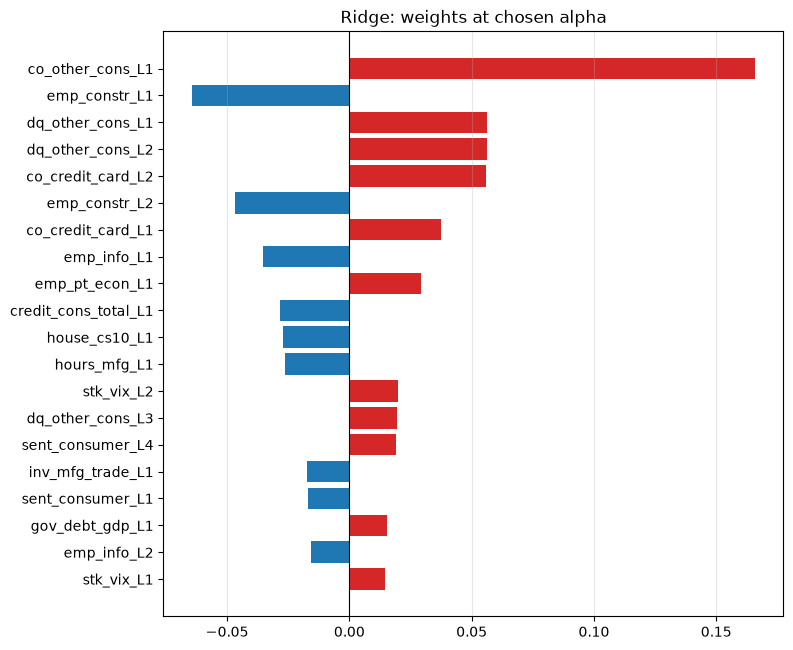

In [8]:
plot_feature_weights(ridge_best, X_train, top=20, title="Ridge: weights at chosen alpha")

In [9]:
record("Ridge", ridge_best, X_train, X_test, y_train, y_test, search=ridge_search,
       notes=f"alpha={ridge_alpha:.3g}")

recorded 'Ridge' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.202,0.142,0.884,0.609,92.0
model - test,0.372,0.169,-1.138,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.127,0.108,0.636,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 3. Lasso (L1)

In [10]:
lasso_pipe = make_pipeline(*preprocess(scale=True), Lasso(max_iter=50_000))
lasso_search = tune(lasso_pipe, {"lasso__alpha": np.logspace(-4, 1, 40)}, X_train, y_train)
lasso_best = lasso_search.best_estimator_
lasso_alpha = lasso_search.best_params_["lasso__alpha"]

best params: {'lasso__alpha': np.float64(0.020309176209047347)}
best CV root_mean_squared_error: 0.3364


<Axes: title={'center': 'Tuning: alpha'}, xlabel='alpha', ylabel='root mean squared error'>

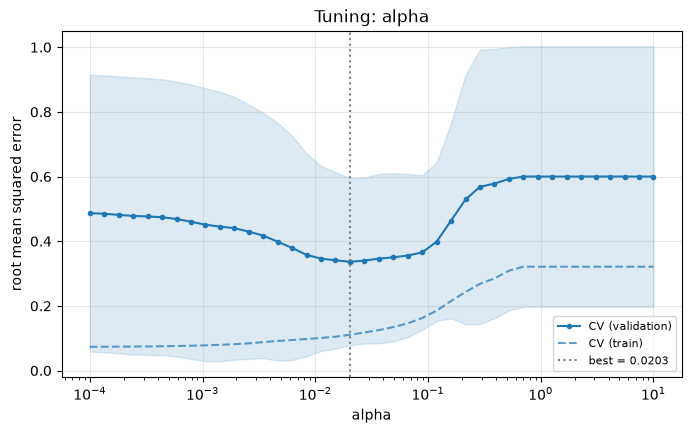

In [11]:
plot_tuning(lasso_search, "lasso__alpha")

#### 1. Alpha Change w Each Weight

<Axes: title={'center': "How each feature's weight changes with the hyperparameter"}, xlabel='lasso__alpha', ylabel='weight (per 1 sd of feature)'>

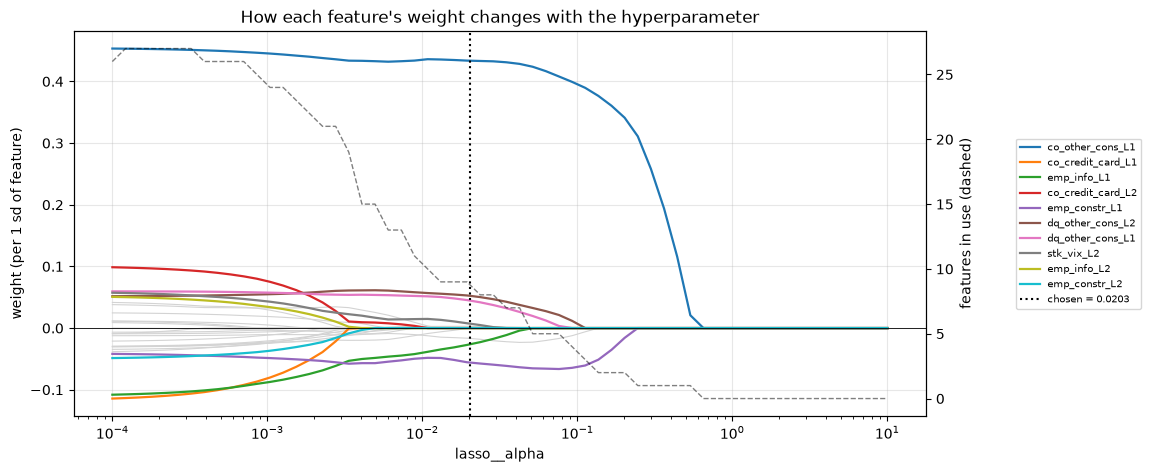

In [12]:
lasso_path = weight_path(lasso_pipe, "lasso__alpha", np.logspace(-4, 1, 60), X_train, y_train)
plot_weight_path(lasso_path, best=lasso_alpha)

> **Note:** Read right to left: at high alpha every weight is 0; as alpha falls, features **enter one at a time**. The first to enter carry the strongest, most consistent signal.

In [13]:
# order in which features enter the model (largest alpha at which each is non-zero)
active = lasso_path.abs() > 1e-12
enters_at = active.apply(lambda col: col[col].index.max() if col.any() else np.nan)
entry_order = (enters_at.dropna().sort_values(ascending=False)
               .rename("enters at alpha").to_frame()
               .assign(**{"in chosen model": lambda d: d.index.isin(
                   feature_weights(lasso_best, X_train).query("used")["feature"])}))
entry_order.head(20)

,enters at alpha,in chosen model
feature,,
co_other_cons_L1,0.535567,True
emp_constr_L1,0.201876,True
hours_mfg_L1,0.112421,True
dq_other_cons_L2,0.092491,True
dq_other_cons_L1,0.076095,True
emp_pt_econ_L1,0.042376,True
emp_info_L1,0.042376,True
stk_vix_L2,0.028683,True
house_cs10_L1,0.019415,False


#### 2. Features Kept

In [14]:
lw = feature_weights(lasso_best, X_train)
print(f"Lasso kept {int(lw['used'].sum())} of {len(lw)} lagged features at alpha = {lasso_alpha:.3g}")
lw[lw["used"]]

Lasso kept 8 of 27 lagged features at alpha = 0.0203


,feature,weight,abs weight,used,variable
0,co_other_cons_L1,0.433520,0.433520,True,co_other_cons
1,emp_constr_L1,-0.056287,0.056287,True,emp_constr
2,dq_other_cons_L2,0.052460,0.052460,True,dq_other_cons
3,dq_other_cons_L1,0.044679,0.044679,True,dq_other_cons
4,emp_info_L1,-0.026291,0.026291,True,emp_info
5,hours_mfg_L1,-0.016644,0.016644,True,hours_mfg
6,stk_vix_L2,0.007064,0.007064,True,stk_vix
7,emp_pt_econ_L1,0.002861,0.002861,True,emp_pt_econ


<Axes: title={'center': 'Lasso: weights at chosen alpha (grey = dropped)'}>

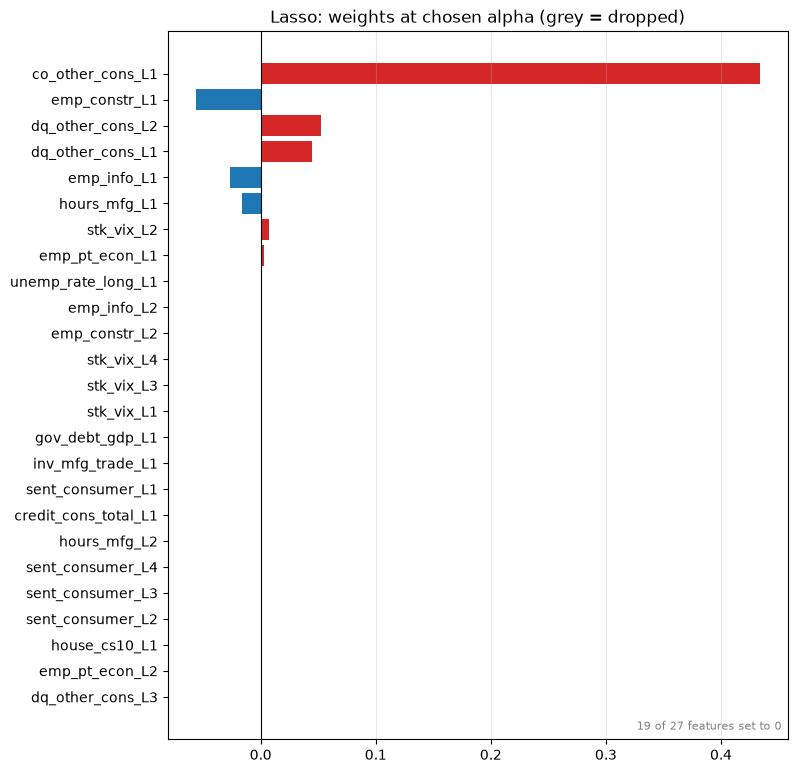

In [15]:
plot_feature_weights(lasso_best, X_train, top=25, title="Lasso: weights at chosen alpha (grey = dropped)")

In [16]:
# which lag of each variable survived?
feature_weights(lasso_best, X_train, by_variable=True)

,total abs weight,lags used,lags available
variable,,,
co_other_cons,0.433520,1,1
dq_other_cons,0.097140,2,3
emp_constr,0.056287,1,2
emp_info,0.026291,1,2
hours_mfg,0.016644,1,2
stk_vix,0.007064,1,4
emp_pt_econ,0.002861,1,2
co_credit_card,0.000000,0,2
credit_cons_total,0.000000,0,1


#### 3. Overfitting

,full-training weight,mean across folds,sd across folds,share of folds used,sign flips
feature,,,,,
co_other_cons_L1,0.433520,0.185177,0.151266,1.0,False
emp_constr_L1,-0.056287,-0.025362,0.024859,0.6,False
dq_other_cons_L2,0.052460,0.024550,0.023935,1.0,False
dq_other_cons_L1,0.044679,0.018991,0.019698,1.0,False
emp_info_L1,-0.026291,-0.022897,0.023315,0.6,False
hours_mfg_L1,-0.016644,-0.002544,0.004414,0.4,False
stk_vix_L2,0.007064,0.019214,0.033443,0.4,False
emp_pt_econ_L1,0.002861,0.000000,0.000000,0.0,False
dq_other_cons_L3,-0.000000,0.002529,0.004829,0.6,False


<Axes: title={'center': 'Weight stability across time folds (dots = folds, bar = full training)'}>

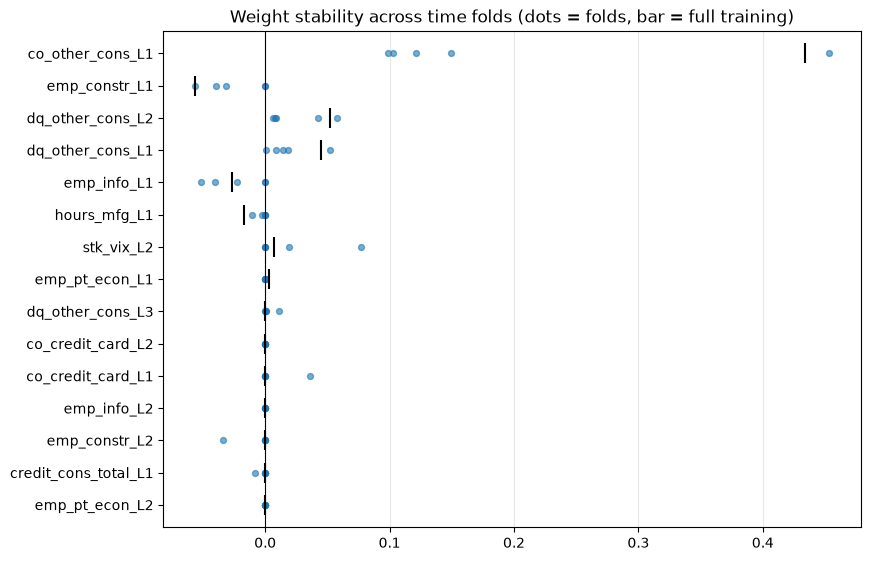

In [17]:
W_lasso, stab_lasso = weight_stability(lasso_best, X_train, y_train)
display(stab_lasso.head(15))
plot_weight_stability(W_lasso, top=15)

> **Note:** A feature kept in every fold with the same sign is a reliable signal. One kept in only some folds, or that flips sign, is being picked up from noise in particular periods.

In [18]:
score(lasso_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.174,0.107,0.914,0.717,92.0
model - test,0.207,0.114,0.339,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.097,0.076,0.790,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


In [19]:
record("Lasso", lasso_best, X_train, X_test, y_train, y_test, search=lasso_search,
       notes=f"alpha={lasso_alpha:.3g}; kept {int(lw['used'].sum())} of {len(lw)} features")

recorded 'Lasso' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.174,0.107,0.914,0.717,92.0
model - test,0.207,0.114,0.339,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.097,0.076,0.790,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 3. Elastic Net (L1 + L2)
`l1_ratio` = 1 is pure Lasso, values near 0 behave like Ridge. Both it and alpha are tuned.

In [20]:
en_pipe = make_pipeline(*preprocess(scale=True), ElasticNet(max_iter=50_000))
en_grid = {"elasticnet__alpha": np.logspace(-4, 1, 25),
           "elasticnet__l1_ratio": [0.1, 0.5, 0.9, 1.0]}   # 4 values keep the chart readable; add more if you like
en_search = tune(en_pipe, en_grid, X_train, y_train)
en_best = en_search.best_estimator_
en_alpha = en_search.best_params_["elasticnet__alpha"]
en_l1 = en_search.best_params_["elasticnet__l1_ratio"]

best params: {'elasticnet__alpha': np.float64(0.019573417814876617), 'elasticnet__l1_ratio': 1.0}
best CV root_mean_squared_error: 0.3368


<Axes: title={'center': 'Tuning: alpha by l1_ratio'}, xlabel='alpha', ylabel='root mean squared error'>

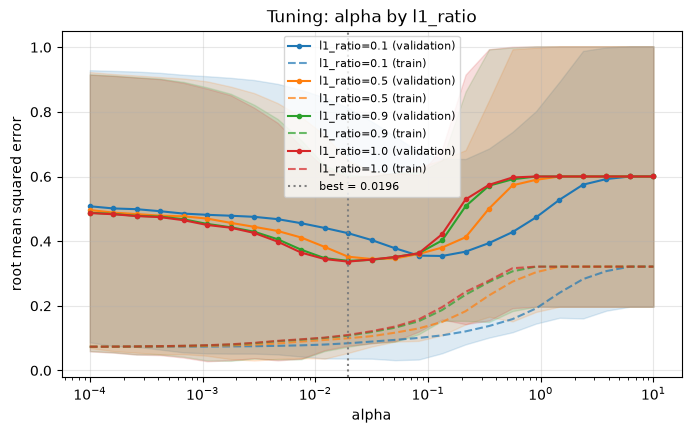

In [21]:
plot_tuning(en_search, "elasticnet__alpha", by="elasticnet__l1_ratio")

<Axes: title={'center': 'Tuning: l1_ratio'}, xlabel='l1_ratio', ylabel='root mean squared error'>

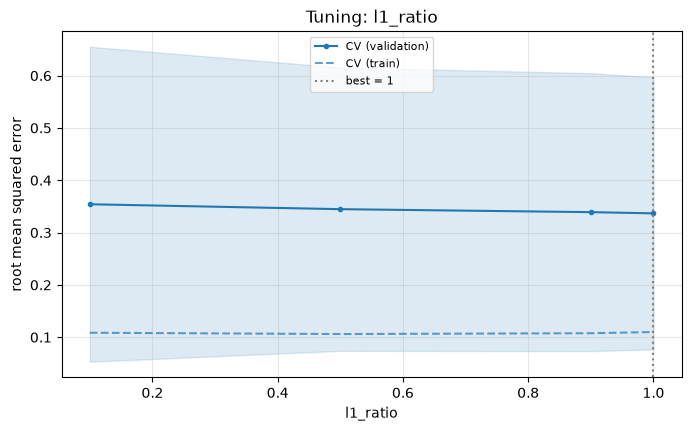

In [22]:
plot_tuning(en_search, "elasticnet__l1_ratio")

> **Note:** If the best `l1_ratio` is 1.0, Elastic Net collapses to Lasso; if it is small, the data prefers Ridge-like shrinkage. 

#### 2. Alpha Change w Each Weight

<Axes: title={'center': "How each feature's weight changes with the hyperparameter"}, xlabel='elasticnet__alpha', ylabel='weight (per 1 sd of feature)'>

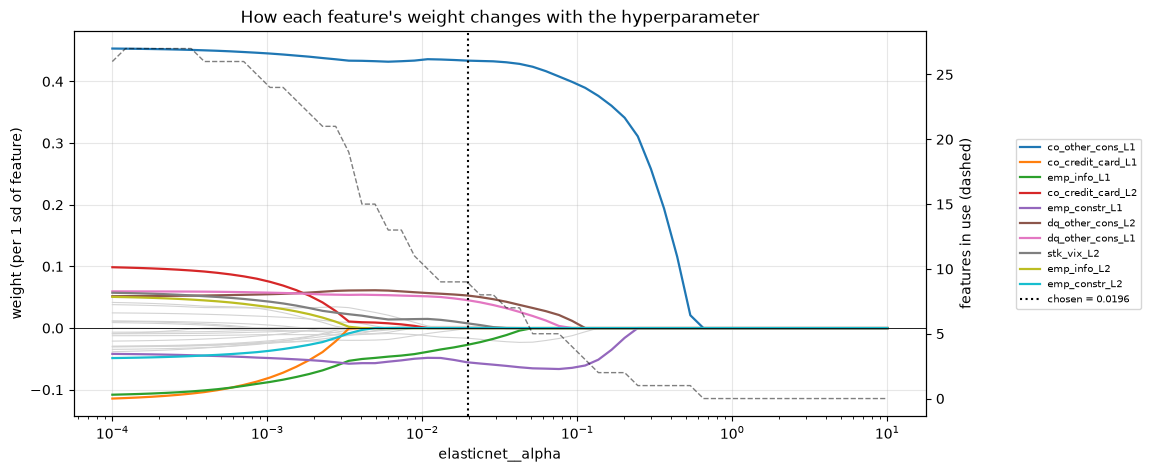

In [23]:
en_path = weight_path(make_pipeline(*preprocess(scale=True), ElasticNet(l1_ratio=en_l1, max_iter=50_000)),
                      "elasticnet__alpha", np.logspace(-4, 1, 60), X_train, y_train)
plot_weight_path(en_path, best=en_alpha)

Elastic Net kept 9 of 27 features (alpha=0.0196, l1_ratio=1.0)


<Axes: title={'center': 'Elastic Net: weights at chosen settings'}>

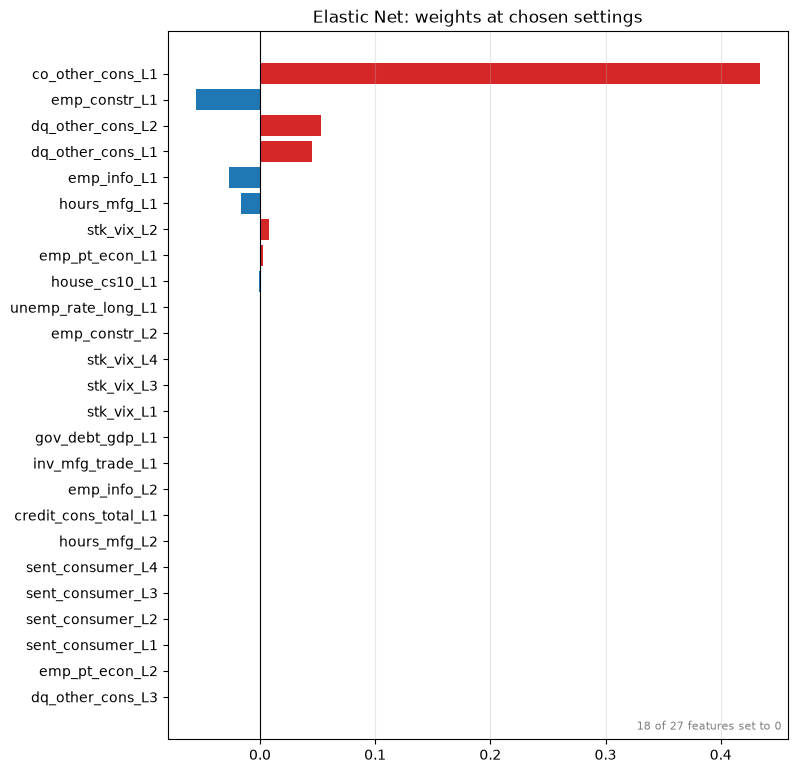

In [26]:
ew = feature_weights(en_best, X_train)
print(f"Elastic Net kept {int(ew['used'].sum())} of {len(ew)} features "
      f"(alpha={en_alpha:.3g}, l1_ratio={en_l1})")
plot_feature_weights(en_best, X_train, top=25, title="Elastic Net: weights at chosen settings")

In [24]:
score(en_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.174,0.107,0.915,0.717,92.0
model - test,0.207,0.114,0.340,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.097,0.077,0.789,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


In [27]:
record("Elastic Net", en_best, X_train, X_test, y_train, y_test, search=en_search,
       notes=f"alpha={en_alpha:.3g}, l1_ratio={en_l1}; kept {int(ew['used'].sum())} of {len(ew)}")

recorded 'Elastic Net' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.174,0.107,0.915,0.717,92.0
model - test,0.207,0.114,0.340,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.097,0.077,0.789,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 4. 3 Models Compared

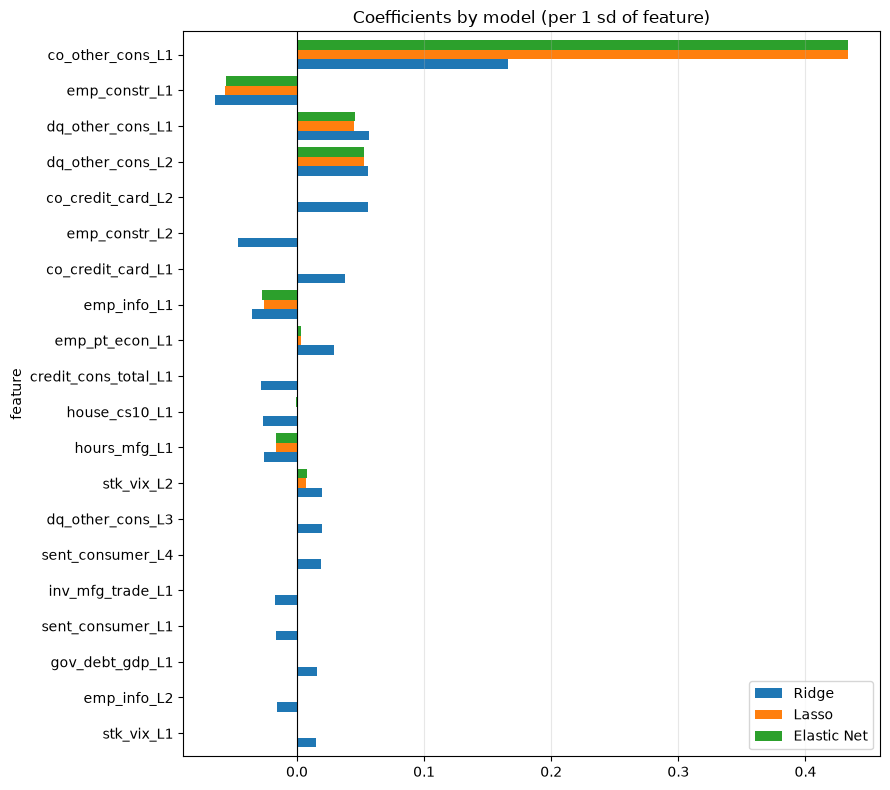

,features used,sum |coef|
Ridge,27.0,0.793
Lasso,8.0,0.640
Elastic Net,9.0,0.642


In [28]:
models = {"Ridge": ridge_best, "Lasso": lasso_best, "Elastic Net": en_best}
coefs = pd.DataFrame({k: feature_weights(m, X_train).set_index("feature")["weight"] for k, m in models.items()})
top = coefs.abs().max(axis=1).sort_values(ascending=False).index[:20]

ax = coefs.loc[top[::-1]].plot.barh(figsize=(9, 8), width=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Coefficients by model (per 1 sd of feature)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

pd.DataFrame({k: {"features used": int((coefs[k].abs() > 1e-12).sum()),
                  "sum |coef|": coefs[k].abs().sum().round(3)} for k in coefs}).T

In [29]:
# which variables (lags added up) each model leans on
pd.DataFrame({k: feature_weights(m, X_train, by_variable=True)["total abs weight"] for k, m in models.items()}) \
  .sort_values("Lasso", ascending=False).round(4).head(15)

,Ridge,Lasso,Elastic Net
variable,,,
co_other_cons,0.1659,0.4335,0.4337
dq_other_cons,0.1319,0.0971,0.0981
emp_constr,0.1111,0.0563,0.0556
emp_info,0.0511,0.0263,0.0271
hours_mfg,0.0302,0.0166,0.0164
stk_vix,0.0396,0.0071,0.0077
emp_pt_econ,0.0334,0.0029,0.0029
co_credit_card,0.0932,0.0000,0.0000
credit_cons_total,0.0286,0.0000,0.0000


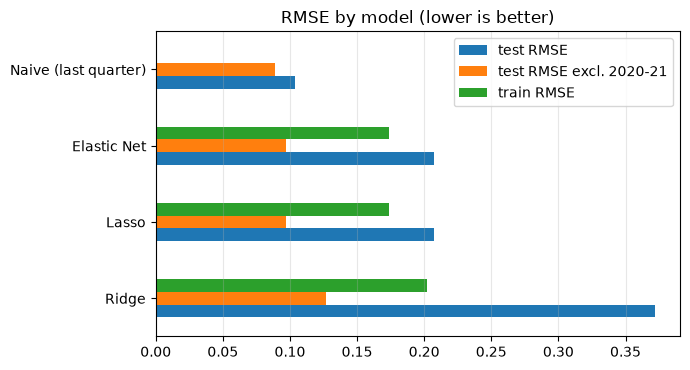

,type,test RMSE,test MAE,test R2,test DirAcc,test RMSE excl. 2020-21,train RMSE,overfit gap (test - train RMSE),CV score,CV metric,best params,saved
Naive (last quarter),baseline,0.104,0.066,0.832,NaN,0.089,NaN,NaN,NaN,NaN,NaN,NaN
Elastic Net,regressor,0.207,0.114,0.34,0.636,0.097,0.174,0.033,0.336756,root_mean_squared_error,"{'elasticnet__alpha': 0.019573417814876617, 'e...",2026-10-18 02:11
Lasso,regressor,0.207,0.114,0.339,0.636,0.097,0.174,0.033,0.336352,root_mean_squared_error,{'lasso__alpha': 0.020309176209047347},2026-10-18 02:06
Ridge,regressor,0.372,0.169,-1.138,0.614,0.127,0.202,0.17,0.384148,root_mean_squared_error,{'ridge__alpha': 32.57020655659783},2026-10-18 02:00


In [30]:
nb2 = ["Ridge", "Lasso", "Elastic Net"]
compare(results={k: v for k, v in load_results().items() if k in nb2})

<Axes: title={'center': 'Test-period forecasts by model'}, ylabel='co_other_cons'>

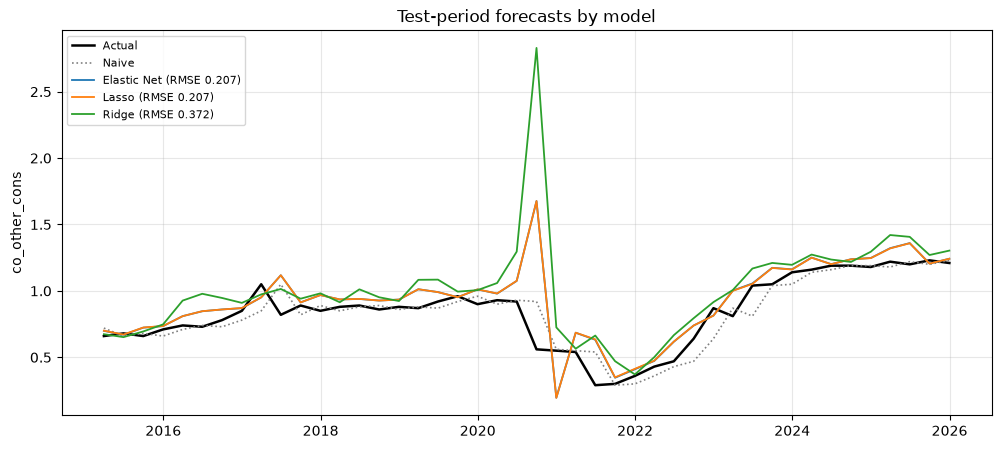

In [31]:
plot_forecasts(names=nb2)

#### 1. Permutation Importance Comparison

best on test RMSE: Lasso


<Axes: title={'center': 'Permutation importance (big train, small test = likely overfit)'}, xlabel='drop in root_mean_squared_error when shuffled'>

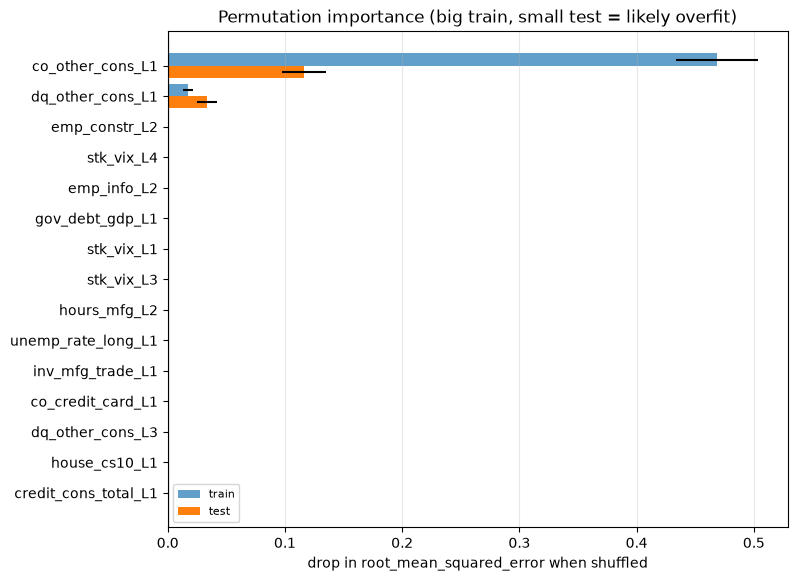

In [32]:
best_name = min(nb2, key=lambda k: load_results()[k]["metrics"].loc["model - test", "RMSE"])
print("best on test RMSE:", best_name)
plot_permutation(permutation_table(models[best_name], X_train, y_train, X_test, y_test, n_repeats=20), top=15)

In [33]:
for k, m in models.items():
    export_predictions(m, X_train, X_test, y_train, y_test, name=k)
coefs.to_csv(f"{EXPORT_DIR}/nb2_coefficients.csv")

saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Ridge_predictions.csv
saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Lasso_predictions.csv
saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Elastic_Net_predictions.csv


### 5. Notes

- **Penalty behaviour:** Ridge kept every feature with shrunken weights; Lasso kept *k* of *n* (entry-order table shows which matter most); Elastic Net's best `l1_ratio` says whether the data prefers selection or shrinkage.
- **Lags:** the by-variable table shows which timing of each variable survived (e.g. Lasso keeping `dq_other_cons_L1` but dropping L2/L3 means last quarter's delinquency is what matters).
- **Overfitting:** validation curves (train dashed vs CV), stability across folds, permutation train vs test, and the train–test RMSE gap in `compare()`.
- **Hyperparameters:** chosen alpha (and l1_ratio) and what they mean: how many features survive and how strongly the rest are shrunk.